In [ ]:
!pip install pyspark

In [ ]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import *

import pandas as pd

In [ ]:
spark = SparkSession.builder \
    .appName("BigData_Sales_Analytics") \
    .master("local[*]") \
    .getOrCreate()

print("Spark is running!")
print("Spark version:", spark.version)

Spark is running!
Spark version: 4.0.5


In [16]:
data = [
    (1, "Laptop", "Tunis", 1200),
    (2, "Phone", "Sfax", 800),
    (3, "Laptop", "Sousse", 1500),
    (4, "Tablet", "Tunis", 600),
    (5, "Phone", "Monastir", 900)
]

columns = ["id", "product", "region", "sales"]

df = spark.createDataFrame(data, columns)

df.printSchema()
df.show()

root
 |-- id: long (nullable = true)
 |-- product: string (nullable = true)
 |-- region: string (nullable = true)
 |-- sales: long (nullable = true)

+---+-------+--------+-----+
| id|product|  region|sales|
+---+-------+--------+-----+
|  1| Laptop|   Tunis| 1200|
|  2|  Phone|    Sfax|  800|
|  3| Laptop|  Sousse| 1500|
|  4| Tablet|   Tunis|  600|
|  5|  Phone|Monastir|  900|
+---+-------+--------+-----+



In [17]:
df.select("product", "sales").show()

+-------+-----+
|product|sales|
+-------+-----+
| Laptop| 1200|
|  Phone|  800|
| Laptop| 1500|
| Tablet|  600|
|  Phone|  900|
+-------+-----+



In [18]:
df.filter(df.sales>900).show()

+---+-------+------+-----+
| id|product|region|sales|
+---+-------+------+-----+
|  1| Laptop| Tunis| 1200|
|  3| Laptop|Sousse| 1500|
+---+-------+------+-----+



In [19]:
df.groupBy("product") \
  .agg(sum("sales").alias("total_sales")) \
  .show()

+-------+-----------+
|product|total_sales|
+-------+-----------+
|  Phone|       1700|
| Laptop|       2700|
| Tablet|        600|
+-------+-----------+



In [20]:
import pandas as pd

data = {
    "OrderID": [1, 2, 3, 4, 5],
    "Product": ["Laptop", "Phone", "Chair", "Laptop", "Table"],
    "Category": ["Electronics", "Electronics", "Furniture",
                 "Electronics", "Furniture"],
    "Region": ["Tunis", "Sfax", "Sousse", "Tunis", "Monastir"],
    "Quantity": [2, 3, 5, 1, 2],
    "Price": [1200, 800, 150, 1200, 300]
}

pdf = pd.DataFrame(data)

pdf.to_csv("sales.csv", index=False)

In [21]:
df = spark.read.csv(
    "sales.csv",
    header=True,
    inferSchema=True
)

df.show()

+-------+-------+-----------+--------+--------+-----+
|OrderID|Product|   Category|  Region|Quantity|Price|
+-------+-------+-----------+--------+--------+-----+
|      1| Laptop|Electronics|   Tunis|       2| 1200|
|      2|  Phone|Electronics|    Sfax|       3|  800|
|      3|  Chair|  Furniture|  Sousse|       5|  150|
|      4| Laptop|Electronics|   Tunis|       1| 1200|
|      5|  Table|  Furniture|Monastir|       2|  300|
+-------+-------+-----------+--------+--------+-----+



In [22]:
df.count()

5

In [23]:
df.columns

['OrderID', 'Product', 'Category', 'Region', 'Quantity', 'Price']

In [27]:
from pyspark.sql.functions import col
df.withColumn("Total",col("Quantity") * col("Price")).show()

+-------+-------+-----------+--------+--------+-----+-----+
|OrderID|Product|   Category|  Region|Quantity|Price|Total|
+-------+-------+-----------+--------+--------+-----+-----+
|      1| Laptop|Electronics|   Tunis|       2| 1200| 2400|
|      2|  Phone|Electronics|    Sfax|       3|  800| 2400|
|      3|  Chair|  Furniture|  Sousse|       5|  150|  750|
|      4| Laptop|Electronics|   Tunis|       1| 1200| 1200|
|      5|  Table|  Furniture|Monastir|       2|  300|  600|
+-------+-------+-----------+--------+--------+-----+-----+



In [28]:
data = [
    (1, "Laptop", "Tunis", 2, 1200),
    (2, "Phone", "Sfax", 3, 800),
    (3, None, "Sousse", 5, 150),
    (4, "Laptop", "Tunis", 2, 1200),
    (5, "Tablet", None, 2, 300),
    (6, "Phone", "Monastir", None, 900)
]

columns = ["OrderID", "Product", "Region", "Quantity", "Price"]

df_dirty = spark.createDataFrame(data, columns)

df_dirty.show()

+-------+-------+--------+--------+-----+
|OrderID|Product|  Region|Quantity|Price|
+-------+-------+--------+--------+-----+
|      1| Laptop|   Tunis|       2| 1200|
|      2|  Phone|    Sfax|       3|  800|
|      3|   NULL|  Sousse|       5|  150|
|      4| Laptop|   Tunis|       2| 1200|
|      5| Tablet|    NULL|       2|  300|
|      6|  Phone|Monastir|    NULL|  900|
+-------+-------+--------+--------+-----+



In [29]:
df_dirty.filter(col("Product").isNull()).show()

+-------+-------+------+--------+-----+
|OrderID|Product|Region|Quantity|Price|
+-------+-------+------+--------+-----+
|      3|   NULL|Sousse|       5|  150|
+-------+-------+------+--------+-----+



In [30]:
from pyspark.sql.functions import col, sum

df_dirty.select([
    sum(col(c).isNull().cast("int")).alias(c)
    for c in df_dirty.columns
]).show()

+-------+-------+------+--------+-----+
|OrderID|Product|Region|Quantity|Price|
+-------+-------+------+--------+-----+
|      0|      1|     1|       1|    0|
+-------+-------+------+--------+-----+



In [31]:
df_clean = df_dirty.dropna()

df_clean.show()

+-------+-------+------+--------+-----+
|OrderID|Product|Region|Quantity|Price|
+-------+-------+------+--------+-----+
|      1| Laptop| Tunis|       2| 1200|
|      2|  Phone|  Sfax|       3|  800|
|      4| Laptop| Tunis|       2| 1200|
+-------+-------+------+--------+-----+



In [32]:
df_clean = df_clean.dropDuplicates()

df_clean.show()

+-------+-------+------+--------+-----+
|OrderID|Product|Region|Quantity|Price|
+-------+-------+------+--------+-----+
|      1| Laptop| Tunis|       2| 1200|
|      2|  Phone|  Sfax|       3|  800|
|      4| Laptop| Tunis|       2| 1200|
+-------+-------+------+--------+-----+



In [33]:
df_clean = df_clean.dropDuplicates(["OrderID"])

In [36]:
from pyspark.sql.functions import col

# Remove rows with missing important values
df_clean = df_dirty.dropna(subset=["Product", "Region", "Quantity"])

# Remove duplicate orders based on OrderID
df_clean = df_clean.dropDuplicates(["OrderID"])

# Display cleaned data
df_clean.show()

# Count rows
print("Rows before cleaning:", df_dirty.count())
print("Rows after cleaning:", df_clean.count())

+-------+-------+------+--------+-----+
|OrderID|Product|Region|Quantity|Price|
+-------+-------+------+--------+-----+
|      1| Laptop| Tunis|       2| 1200|
|      2|  Phone|  Sfax|       3|  800|
|      4| Laptop| Tunis|       2| 1200|
+-------+-------+------+--------+-----+

Rows before cleaning: 6
Rows after cleaning: 3


In [37]:
from pyspark.sql.functions import col, sum as spark_sum, avg, count

# Create Total column
df_sales = df_clean.withColumn(
    "Total",
    col("Quantity") * col("Price")
)

# 1. Total revenue
df_sales.select(
    spark_sum("Total").alias("Total_Revenue")
).show()

# 2. Revenue by region
df_sales.groupBy("Region").agg(
    spark_sum("Total").alias("Revenue")
).show()

# 3. Revenue by product
df_sales.groupBy("Product").agg(
    spark_sum("Total").alias("Revenue")
).show()

# 4. Average order value
df_sales.select(
    avg("Total").alias("Average_Order_Value")
).show()

# 5. Number of orders
print("Number of orders:", df_sales.count())

+-------------+
|Total_Revenue|
+-------------+
|         7200|
+-------------+

+------+-------+
|Region|Revenue|
+------+-------+
| Tunis|   4800|
|  Sfax|   2400|
+------+-------+

+-------+-------+
|Product|Revenue|
+-------+-------+
|  Phone|   2400|
| Laptop|   4800|
+-------+-------+

+-------------------+
|Average_Order_Value|
+-------------------+
|             2400.0|
+-------------------+

Number of orders: 3


In [38]:
import matplotlib.pyplot as plt

# Revenue by region
region_sales = df_sales.groupBy("Region").agg(
    spark_sum("Total").alias("Revenue")
)

# Convert Spark DataFrame to Pandas
region_pdf = region_sales.toPandas()

print(region_pdf)

  Region  Revenue
0  Tunis     4800
1   Sfax     2400


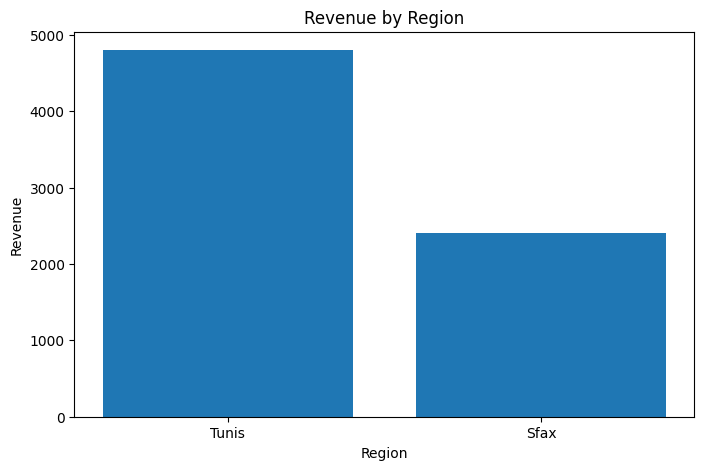

In [39]:
plt.figure(figsize=(8, 5))

plt.bar(region_pdf["Region"], region_pdf["Revenue"])

plt.title("Revenue by Region")
plt.xlabel("Region")
plt.ylabel("Revenue")

plt.show()

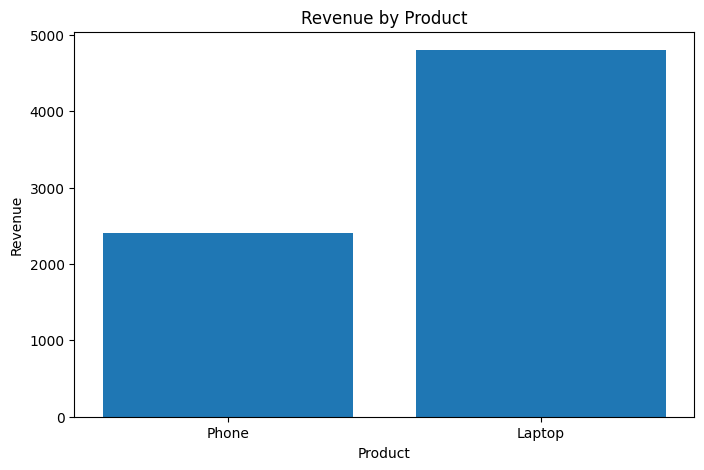

In [40]:
product_pdf = df_sales.groupBy("Product").agg(
    spark_sum("Total").alias("Revenue")
).toPandas()

plt.figure(figsize=(8, 5))

plt.bar(product_pdf["Product"], product_pdf["Revenue"])

plt.title("Revenue by Product")
plt.xlabel("Product")
plt.ylabel("Revenue")

plt.show()

In [41]:
df_sales.write \
    .mode("overwrite") \
    .parquet("sales_parquet")

In [42]:
df_parquet = spark.read.parquet("sales_parquet")

df_parquet.show()
df_parquet.printSchema()

+-------+-------+------+--------+-----+-----+
|OrderID|Product|Region|Quantity|Price|Total|
+-------+-------+------+--------+-----+-----+
|      1| Laptop| Tunis|       2| 1200| 2400|
|      2|  Phone|  Sfax|       3|  800| 2400|
|      4| Laptop| Tunis|       2| 1200| 2400|
+-------+-------+------+--------+-----+-----+

root
 |-- OrderID: long (nullable = true)
 |-- Product: string (nullable = true)
 |-- Region: string (nullable = true)
 |-- Quantity: long (nullable = true)
 |-- Price: long (nullable = true)
 |-- Total: long (nullable = true)



Sales data:
+-------+-------+-----------+--------+--------+-----+-----+
|OrderID|Product|   Category|  Region|Quantity|Price|Total|
+-------+-------+-----------+--------+--------+-----+-----+
|      1| Laptop|Electronics|   Tunis|       2| 1200| 2400|
|      2|  Phone|Electronics|    Sfax|       3|  800| 2400|
|      3|  Chair|  Furniture|  Sousse|       5|  150|  750|
|      4| Laptop|Electronics|   Tunis|       1| 1200| 1200|
|      5|  Table|  Furniture|Monastir|       2|  300|  600|
+-------+-------+-----------+--------+--------+-----+-----+

Revenue by region:
+--------+-------+
|  Region|Revenue|
+--------+-------+
|Monastir|    600|
|   Tunis|   3600|
|    Sfax|   2400|
|  Sousse|    750|
+--------+-------+

Revenue by product:
+-------+-------+
|Product|Revenue|
+-------+-------+
|  Chair|    750|
|  Phone|   2400|
| Laptop|   3600|
|  Table|    600|
+-------+-------+



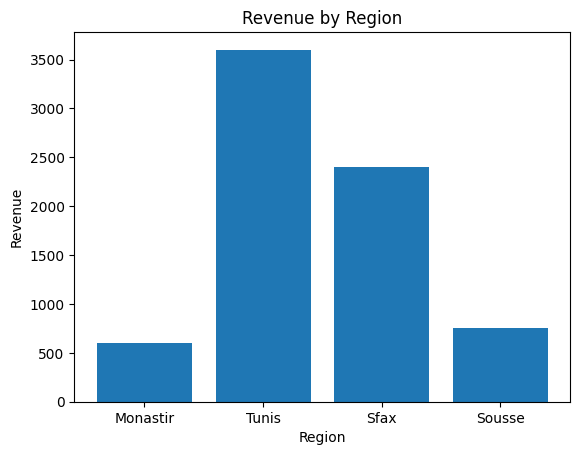

In [43]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import (
    col, sum as spark_sum, avg
)
import matplotlib.pyplot as plt

# 1. Start Spark
spark = SparkSession.builder \
    .appName("BigData_Sales_Analytics") \
    .master("local[*]") \
    .getOrCreate()

# 2. Read CSV
df = spark.read.csv(
    "sales.csv",
    header=True,
    inferSchema=True
)

# 3. Clean data
df = df.dropna(
    subset=["OrderID", "Product", "Region", "Quantity", "Price"]
)

df = df.dropDuplicates(["OrderID"])

# 4. Calculate revenue
df = df.withColumn(
    "Total",
    col("Quantity") * col("Price")
)

# 5. Analyze revenue by region
region_sales = df.groupBy("Region").agg(
    spark_sum("Total").alias("Revenue")
)

# 6. Analyze revenue by product
product_sales = df.groupBy("Product").agg(
    spark_sum("Total").alias("Revenue")
)

# 7. Display results
print("Sales data:")
df.show()

print("Revenue by region:")
region_sales.show()

print("Revenue by product:")
product_sales.show()

# 8. Save results
df.write.mode("overwrite").parquet("sales_results")

# 9. Visualize
region_pdf = region_sales.toPandas()

plt.bar(region_pdf["Region"], region_pdf["Revenue"])
plt.title("Revenue by Region")
plt.xlabel("Region")
plt.ylabel("Revenue")
plt.show()